In [2]:
from pathlib import Path
import os, json, random, subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau
import cv2

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay)

print(f"Tensorflow:{tf.__version__}, OpenCV:{cv2.__version__}")
print(f"GPU:{tf.config.list_physical_devices("GPU")}")

Tensorflow:2.21.0, OpenCV:5.0.0
GPU:[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [18]:
SEED = 42
IMG_SIZE = 224
DEFECT_CUTOFF = 0.5
BATCH_SIZE = 32
EPOCHS = 30
LR = 1e-3

OUT_DIR = Path("outputs"); OUT_DIR.mkdir(parents=True,exist_ok=True)

def set_seeds(seed=SEED):
  random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
  os.environ["PYTHON_HASH_SEED"] = str(SEED)
set_seeds()

# 1. Load model CNN

In [19]:
MODEL_PATH = Path("outputs/basic_cnn.keras")
if MODEL_PATH.exists():
    print("Loaded saved model from", MODEL_PATH)
    model_cnn = tf.keras.models.load_model(MODEL_PATH)

model_cnn    

Loaded saved model from outputs/basic_cnn.keras


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 30 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


<Functional name=small_cnn, built=True>

# 2. Load splitted data

In [20]:
SPLITS = Path("outputs/splits.csv")
if SPLITS.exists():
    print("Loaded splitted data from", SPLITS)
    df = pd.read_csv(SPLITS)

train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
print(f"\nTraining dataset:\n{train_df.head(3)}")
print(f"\nValidation dataset:\n{val_df.head(3)}")
print(f"\nTest dataset:\n{test_df.head(3)}\n")

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} n={len(d):4d} , defect rate={d.label.mean():.3f} , poly defect rate={(d.type=='poly').mean():.3f} , mono defect rate={(d.type=='mono').mean():.3f}")

Loaded splitted data from outputs/splits.csv

Training dataset:
                  path  prob  type  label  split
0  images/cell0512.png   1.0  mono      1  train
1  images/cell2447.png   0.0  poly      0  train
2  images/cell0657.png   0.0  poly      0  train

Validation dataset:
                  path  prob  type  label split
0  images/cell1020.png   0.0  mono      0   val
1  images/cell0094.png   0.0  poly      0   val
2  images/cell1576.png   0.0  mono      0   val

Test dataset:
                  path  prob  type  label split
0  images/cell2415.png   0.0  mono      0  test
1  images/cell0175.png   0.0  poly      0  test
2  images/cell1694.png   0.0  poly      0  test

train n=1836 , defect rate=0.313 , poly defect rate=0.590 , mono defect rate=0.410
val   n= 394 , defect rate=0.315 , poly defect rate=0.591 , mono defect rate=0.409
test  n= 394 , defect rate=0.312 , poly defect rate=0.591 , mono defect rate=0.409


# 3. Create image dataset

In [35]:
def parse_image(path, label):
    # Read the file
    image_bytes = tf.io.read_file(path)
    # Decode image as grayscale (1 channel)
    image = tf.io.decode_png(image_bytes, channels=1)
    # Convert to float32 and normalize to [0, 1]
    image = tf.image.convert_image_dtype(image, tf.float32)
    # Resize to the model's expected size
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return image, label

def create_dataset(dataframe, shuffle=False):
    # Extract file paths and labels
    REPO_DIR = Path("elpv-dataset")
    if REPO_DIR.exists():
        IMAGES_DIR = Path(REPO_DIR / "src/elpv_dataset/data/")
        if IMAGES_DIR.exists():
            paths = [str(IMAGES_DIR / str(p))for p in dataframe["path"].values]
            labels = dataframe['label'].values

    # Create a tensor slice dataset
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    # Map the parsing function
    dataset = dataset.map(parse_image, num_parallel_calls=tf.data.AUTOTUNE)

    # Shuffle only training data
    if shuffle:
        dataset = dataset.shuffle(buffer_size=1024)

    # # Batch and prefetch for hardware efficiency
    dataset = dataset.batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
    return dataset

# Create the dataset pipelines
ds_train = create_dataset(train_df, shuffle=True)
ds_val = create_dataset(val_df, shuffle=False)
ds_test = create_dataset(test_df, shuffle=False)

# 4. Train the model

In [36]:
# train the model
def train_cnn_model(model, ds_train, ds_val, class_weight):
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.5, patience=3),
    ]
  
    model_history= model.fit(ds_train, validation_data= ds_val,
                             epochs=EPOCHS,class_weight=class_weight, callbacks=callbacks, verbose=2)

    return model_history


# plot the metric
def plot_metrics(model, history):
    h = pd.DataFrame(history.history)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    h[["loss", "val_loss"]].plot(ax=ax[0], title="Loss"); h[["pr_auc", "val_pr_auc"]].plot(ax=ax[1], title="PR-AUC")
    plt.tight_layout(); plt.show()

In [37]:
n_pos, n_neg = train_df['label'].sum(), len(train_df['label']) - train_df['label'].sum()
class_weight = {0: len(train_df['label']) / (2 * n_neg), 1: len(train_df['label']) / (2 * n_pos)}
print("class weights:", {k: round(v, 2) for k, v in class_weight.items()})

tf.keras.config.disable_traceback_filtering()

# train the model
history_model_cnn = train_cnn_model(model_cnn,ds_train, ds_val,class_weight)


class weights: {0: np.float64(0.73), 1: np.float64(1.6)}
Epoch 1/30
58/58 - 32s - 556ms/step - loss: 0.6433 - pr_auc: 0.5749 - precision: 0.4904 - recall: 0.6690 - val_loss: 0.7012 - val_pr_auc: 0.2164 - val_precision: 0.2282 - val_recall: 0.5484 - learning_rate: 0.0010
Epoch 2/30
58/58 - 6s - 104ms/step - loss: 0.5752 - pr_auc: 0.6169 - precision: 0.5296 - recall: 0.6847 - val_loss: 0.7755 - val_pr_auc: 0.2156 - val_precision: 0.3147 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/30
58/58 - 6s - 106ms/step - loss: 0.5584 - pr_auc: 0.6376 - precision: 0.5199 - recall: 0.7300 - val_loss: 0.7505 - val_pr_auc: 0.2189 - val_precision: 0.3147 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/30
58/58 - 6s - 102ms/step - loss: 0.5805 - pr_auc: 0.6112 - precision: 0.5269 - recall: 0.7160 - val_loss: 0.7559 - val_pr_auc: 0.2102 - val_precision: 0.2292 - val_recall: 0.5565 - learning_rate: 0.0010
Epoch 5/30
58/58 - 6s - 111ms/step - loss: 0.5421 - pr_auc: 0.6723 - precision: 0.5530 - r

# 5. Visualise Model Accuracy and Loss

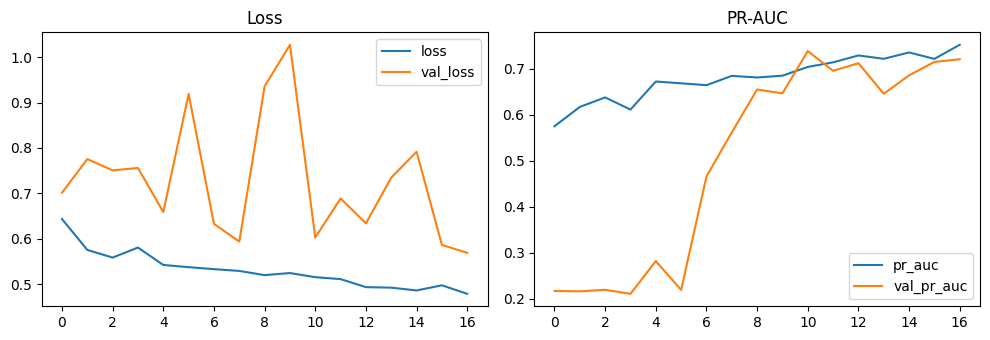

In [39]:
# plot accuracy vs loss metrics
plot_metrics(model_cnn, history_model_cnn)